In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv')

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [7]:
# Check dataset information
df.info()

# Check missing values
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

In [8]:
# Check unique values in horsepower
print(df['horsepower'].unique())

['130' '165' '150' '140' '198' '220' '215' '225' '190' '170' '160' '95'
 '97' '85' '88' '46' '87' '90' '113' '200' '210' '193' '?' '100' '105'
 '175' '153' '180' '110' '72' '86' '70' '76' '65' '69' '60' '80' '54'
 '208' '155' '112' '92' '145' '137' '158' '167' '94' '107' '230' '49' '75'
 '91' '122' '67' '83' '78' '52' '61' '93' '148' '129' '96' '71' '98' '115'
 '53' '81' '79' '120' '152' '102' '108' '68' '58' '149' '89' '63' '48'
 '66' '139' '103' '125' '133' '138' '135' '142' '77' '62' '132' '84' '64'
 '74' '116' '82']


In [9]:
# Replace ? with NaN
df['horsepower'] = df['horsepower'].replace('?', np.nan)

In [10]:
print(df['horsepower'].isnull().sum())

6


In [11]:
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')

In [12]:
mean_hp = df['horsepower'].mean()

print(mean_hp)

104.46938775510205


In [13]:
# Convert horsepower to numeric values
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')

# Check data type
print(df['horsepower'].dtype)

# Calculate mean
mean_hp = df['horsepower'].mean()

print("Mean Horsepower:", mean_hp)

float64
Mean Horsepower: 104.46938775510205


In [14]:
df['horsepower'] = df['horsepower'].fillna(mean_hp)

In [15]:
print(df['horsepower'].isnull().sum())

0


In [16]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino


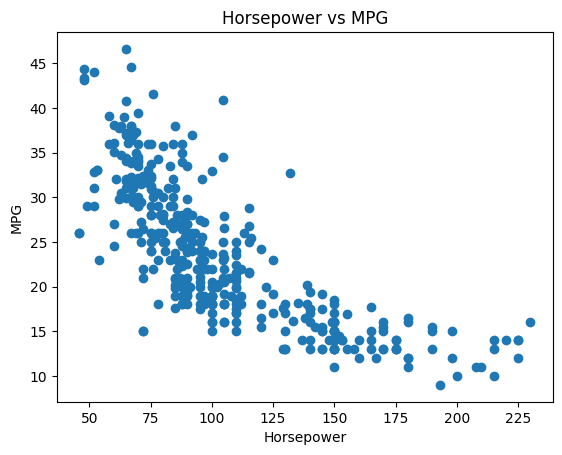

In [17]:
plt.scatter(df['horsepower'], df['mpg'])
plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.title('Horsepower vs MPG')
plt.show()

In [18]:
X = df[['horsepower']]
y = df['mpg']

In [19]:
print(X.shape)
print(y.shape)

(398, 1)
(398,)


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [21]:
print(X_train.shape)
print(X_test.shape)

(318, 1)
(80, 1)


In [22]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [23]:
print(X_train_poly[:5])

[[1.000e+00 1.500e+02 2.250e+04]
 [1.000e+00 8.800e+01 7.744e+03]
 [1.000e+00 6.800e+01 4.624e+03]
 [1.000e+00 6.000e+01 3.600e+03]
 [1.000e+00 9.500e+01 9.025e+03]]


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_poly)

X_test_scaled = scaler.transform(X_test_poly)

In [25]:
print(X_train_scaled[:5])

[[ 0.          1.26183446  1.12354675]
 [ 0.         -0.41351298 -0.46160689]
 [ 0.         -0.95394763 -0.79677085]
 [ 0.         -1.1701215  -0.90677338]
 [ 0.         -0.22436085 -0.32399631]]


In [26]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

In [27]:
# Number of features
n_features = X_train_scaled.shape[1]

# Initialize weights with zeros
weights = np.zeros(n_features)

# Initialize bias
bias = 0.0

print(weights)
print(bias)

[0. 0. 0.]
0.0


In [28]:
y_pred = X_train_scaled @ weights + bias

print(y_pred[:5])

[0. 0. 0. 0. 0.]


In [29]:
error = mse(y_train, y_pred)

print("Initial Error:", error)

Initial Error: 620.0422012578616


In [30]:
n = len(y_train)

gradients = (2 / n) * (X_train_scaled.T @ (y_pred - y_train))

print(gradients)

[ 0.         12.09415868 11.09491374]


In [31]:
learning_rate = 0.01

weights = weights - learning_rate * gradients

print(weights)

[ 0.         -0.12094159 -0.11094914]


In [32]:
y_pred = X_train_scaled @ weights + bias

error = mse(y_train, y_pred)

print("New Error:", error)

New Error: 617.4018459465494


In [33]:

weights = np.zeros(n_features)
bias = 0.0

In [34]:
epochs = 1000
learning_rate = 0.01
momentum = 0.9

velocity_weights = np.zeros(n_features)
velocity_bias = 0.0

In [35]:
loss_history = []

In [44]:
for epoch in range(epochs):

    # Calculate predictions
    y_pred = X_train_scaled @ weights + bias

    # Calculate gradients
    gradients = (2 / n) * (X_train_scaled.T @ (y_pred - y_train))
    bias_gradient = (2 / n) * np.sum(y_pred - y_train)

    # Update using Momentum
    velocity_weights = momentum * velocity_weights + learning_rate * gradients
    velocity_bias = momentum * velocity_bias + learning_rate * bias_gradient

    weights = weights - velocity_weights
    bias = bias - velocity_bias

    # Calculate error
    y_pred = X_train_scaled @ weights + bias
    error = mse(y_train, y_pred)
    loss_history.append(error)

    if epoch % 100 == 0:
        print("Epoch:", epoch, "Error:", error)

Epoch: 0 Error: 21.680769336956534
Epoch: 100 Error: 21.67804122361752
Epoch: 200 Error: 21.676722260001615
Epoch: 300 Error: 21.67608457937625
Epoch: 400 Error: 21.67577627930257
Epoch: 500 Error: 21.675627225165364
Epoch: 600 Error: 21.675555161816316
Epoch: 700 Error: 21.675520321278697
Epoch: 800 Error: 21.67550347689
Epoch: 900 Error: 21.675495333116977


In [37]:
y_test_pred = X_test_scaled @ weights + bias

test_error = mse(y_test, y_test_pred)

print("Test MSE:", test_error)

Test MSE: 13.729953673485095


In [38]:
rmse = np.sqrt(test_error)

print("Test RMSE:", rmse)

Test RMSE: 3.7053952115105204


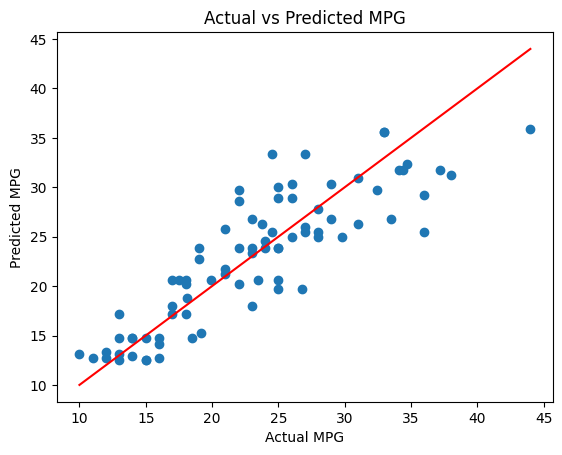

In [39]:
plt.scatter(y_test, y_test_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG")
plt.show()

In [40]:
loss_history = []

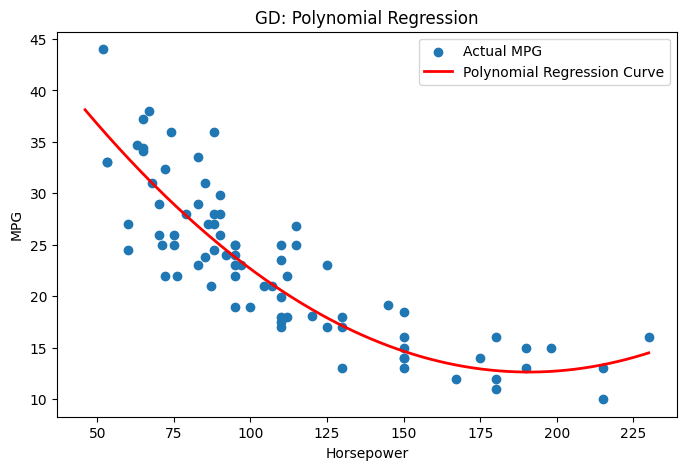

In [46]:
horsepower_range = np.linspace(
    X['horsepower'].min(),
    X['horsepower'].max(),
    200
).reshape(-1, 1)

horsepower_grid = pd.DataFrame({
    'horsepower': horsepower_range.flatten()
})

horsepower_poly = poly.transform(horsepower_grid)
horsepower_scaled = scaler.transform(horsepower_poly)

predicted_curve = horsepower_scaled @ weights + bias

plt.figure(figsize=(8, 5))

plt.scatter(X_test['horsepower'], y_test, label='Actual MPG')

plt.plot(
    horsepower_range,
    predicted_curve,
    color='red',
    linewidth=2,
    label='Polynomial Regression Curve'
)

plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.title('GD: Polynomial Regression')
plt.legend()
plt.show()

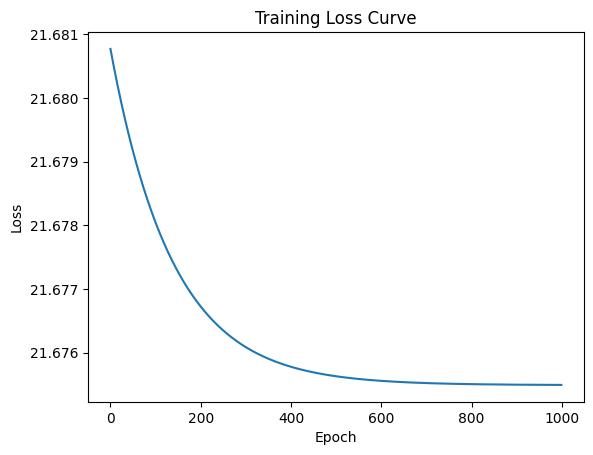

In [45]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.show()

In [43]:
print("Number of loss values:", len(loss_history))

Number of loss values: 0
